--- Kinetic Fit Results ---
Time Constant k (V_o/K): 0.000305 s⁻¹
Fitted Initial OD (OD_0): 1.4694
R-squared (Goodness of Fit): 0.992333
Total experiment duration: 108.89 minutes


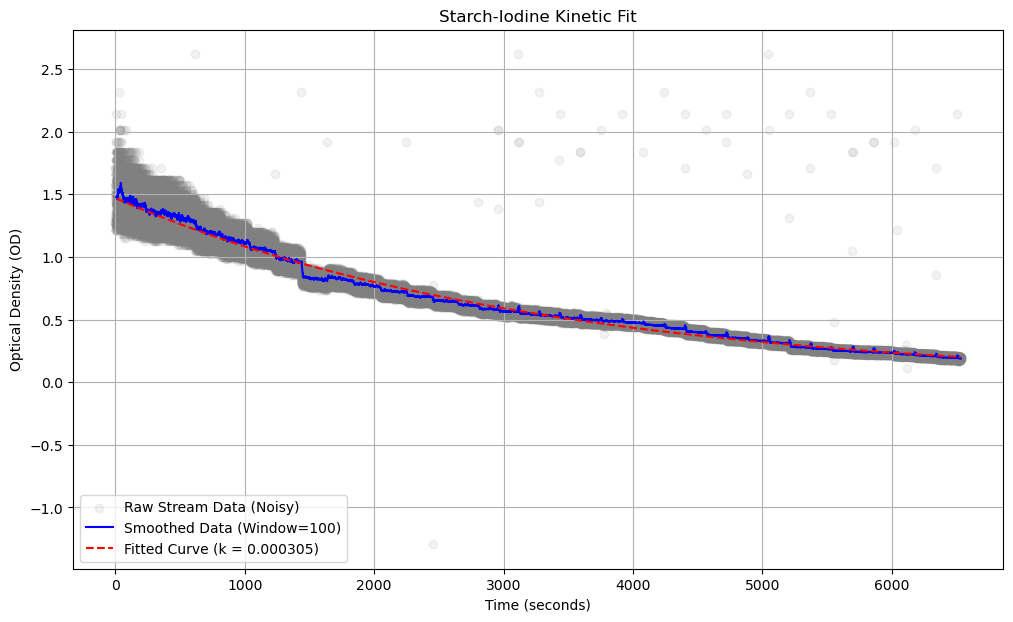

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --- Configuration ---
FILENAME = 'od_stream_data_20251111_234938.csv'
# This window size is for the moving average.
# Increase for more smoothing, decrease for faster response.
ROLLING_WINDOW = 100 

def fit_reaction_kinetics(filename, window_size):
    """
    Loads and analyzes the starch-iodine decomposition data
    to find the reaction time constant k (V_o / K).
    """
    
    # --- 1. Load and Prepare Data ---
    try:
        df = pd.read_csv(filename)
    except FileNotFoundError:
        print(f"Error: File not found. Make sure '{filename}' is in the same directory.")
        return

    # Convert the time column from string to datetime objects
    df['time'] = pd.to_datetime(df['time'])
    df = df.sort_values(by='time')

    # Create an 'elapsed_seconds' column (this is 't' in the equation)
    start_time = df['time'].iloc[0]
    df['elapsed_seconds'] = (df['time'] - start_time).dt.total_seconds()
    
    # --- 2. Smooth the Noisy Data ---
    # We apply a rolling (moving) average to the 'od' column
    # This is critical for getting a good fit from noisy stream data
    df['od_smooth'] = df['od'].rolling(window=window_size).mean()

    # Drop the initial rows that are NaN due to the rolling window
    df_fit = df.dropna()
    
    # --- 3. Linearize the Data ---
    # Our model is: OD(t) = OD_0 * e^(-k*t)
    # We linearize it by taking the natural log (ln):
    # ln(OD(t)) = -k*t + ln(OD_0)
    # This is a line: y = m*x + c
    # y = ln(OD(t))
    # x = t (elapsed_seconds)
    # m = -k (our slope)
    
    # We must ignore any OD values <= 0, as ln(0) is undefined
    df_fit = df_fit[df_fit['od_smooth'] > 0].copy()
    
    # Create our 'y' variable
    df_fit['ln_od'] = np.log(df_fit['od_smooth'])

    # --- 4. Perform Linear Regression ---
    x = df_fit['elapsed_seconds']
    y = df_fit['ln_od']
    
    fit = linregress(x, y)
    
    slope = fit.slope
    intercept = fit.intercept
    r_squared = fit.rvalue**2

    # --- 5. Calculate Kinetic Constants ---
    # The slope 'm' is our negative rate constant '-k'
    k = -slope
    
    # The intercept 'c' is ln(OD_0)
    od_0 = np.exp(intercept)
    
    print("--- Kinetic Fit Results ---")
    print(f"Time Constant k (V_o/K): {k:.6f} s⁻¹")
    print(f"Fitted Initial OD (OD_0): {od_0:.4f}")
    print(f"R-squared (Goodness of Fit): {r_squared:.6f}")
    print(f"Total experiment duration: {df['elapsed_seconds'].max() / 60:.2f} minutes")

    # --- 6. Plot the Results ---
    
    # Create a smooth line for the final fitted function
    # Use the original, non-linear formula: OD(t) = OD_0 * e^(-k*t)
    fit_time_x = df_fit['elapsed_seconds']
    fit_od_y = od_0 * np.exp(-k * fit_time_x)

    plt.figure(figsize=(12, 7))
    
    # Plot the raw, noisy data
    plt.scatter(df['elapsed_seconds'], df['od'], 
                label='Raw Stream Data (Noisy)', alpha=0.1, color='gray')
    
    # Plot the smoothed data
    plt.plot(df_fit['elapsed_seconds'], df_fit['od_smooth'], 
             color='blue', label=f'Smoothed Data (Window={window_size})')
    
    # Plot the final fitted exponential curve
    plt.plot(fit_time_x, fit_od_y, color='red', linestyle='--', 
             label=f'Fitted Curve (k = {k:.6f})')
    
    plt.title('Starch-Iodine Kinetic Fit')
    plt.xlabel('Time (seconds)')
    plt.ylabel('Optical Density (OD)')
    plt.legend()
    plt.grid(True)
    plt.show()


# --- Run the Analysis ---
if __name__ == "__main__":
    fit_reaction_kinetics(FILENAME, ROLLING_WINDOW)